FICHIER jupiter  Analyse des donnees.ipynb


2) Affichage des données 

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# ==========================================
# 1. CHARGEMENT DES DONNÉES
# ==========================================
# Charger le fichier MAT téléchargé

chemin_97 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Sains\97.mat"
mat_data_97 = loadmat(chemin_97)
chemin_98 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Sains\98.mat"
mat_data_98 = loadmat(chemin_98)  
chemin_99 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Sains\99.mat"
mat_data_99 = loadmat(chemin_99)
chemin_100 = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\Sains\100.mat"
mat_data_100 = loadmat(chemin_100)



2) Affichage types de donnees

Roulement sans Défauts charge moteur hp=1

In [3]:

print("mat_data_97.keys :")
print(type(mat_data_97))
print(mat_data_97.keys())

print("mat_data_98.keys :")
print(type(mat_data_98))
print(mat_data_98.keys())

print("mat_data_99.keys :")
print(type(mat_data_99))
print(mat_data_99.keys())

print("mat_data_100.keys() :")
print(type(mat_data_100))
print(mat_data_100.keys())


mat_data_97.keys :
<class 'dict'>
dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])
mat_data_98.keys :
<class 'dict'>
dict_keys(['__header__', '__version__', '__globals__', 'X098_DE_time', 'X098_FE_time'])
mat_data_99.keys :
<class 'dict'>
dict_keys(['__header__', '__version__', '__globals__', 'ans', 'X098_DE_time', 'X098_FE_time', 'X099_DE_time', 'X099_FE_time'])
mat_data_100.keys() :
<class 'dict'>
dict_keys(['__header__', '__version__', '__globals__', 'X100_DE_time', 'X100_FE_time', 'X100RPM'])


AFFICHAGE BOXPLOT   

<>:43: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:43: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:52: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:56: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:43: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:43: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:52: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences wil

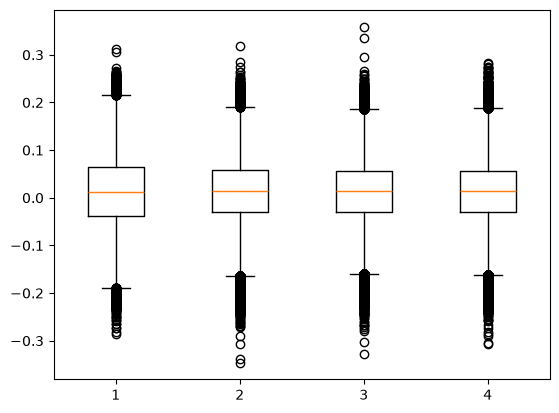

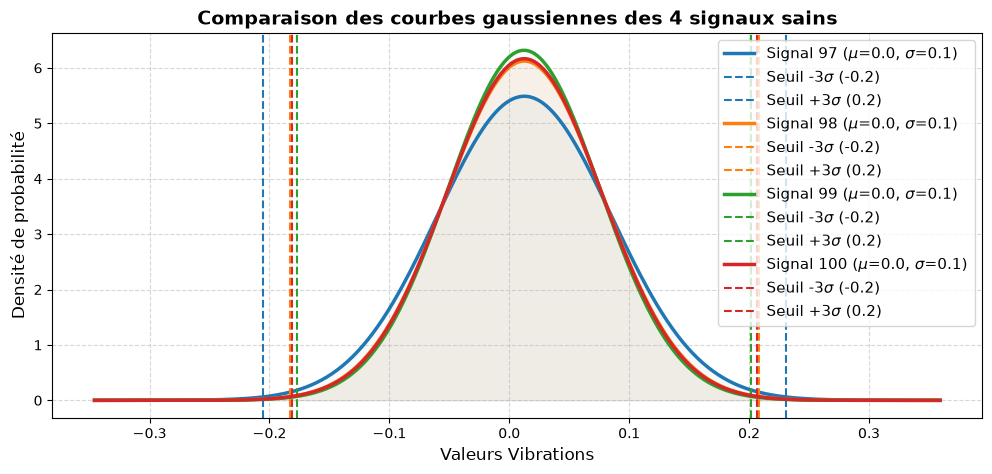

In [14]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X098_DE_time'

signal_97 = mat_data_97['X097_DE_time'].ravel()
signal_98 = mat_data_98['X098_DE_time'].ravel()
signal_99 = mat_data_99['X099_DE_time'].ravel()
signal_100 = mat_data_100['X100_DE_time'].ravel()

plt.boxplot([signal_97, signal_98, signal_99, signal_100], label=['97', '98', '99', '100']);


# Regroupement des signaux dans un dictionnaire pour automatiser le tracé
signaux = {
    'Signal 97': signal_97,
    'Signal 98': signal_98,
    'Signal 99': signal_99,
    'Signal 100': signal_100
}

# 2. Configuration de la figure
plt.figure(figsize=(12, 5))

# Définition d'un axe X global couvrant l'ensemble des données
toutes_valeurs = np.concatenate([signal_97, signal_98, signal_99, signal_100])
x = np.linspace(min(toutes_valeurs), max(toutes_valeurs), 500)

# Couleurs personnalisées pour chaque courbe
couleurs = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# 3. Calcul et tracé de la courbe gaussienne pour chaque série
for (nom, donnees), couleur in zip(signaux.items(), couleurs):
    # Calcul de la moyenne (mu) et de l'écart-type (sigma)
    mu = np.mean(donnees)
    sigma = np.std(donnees)
    
    # Génération de la courbe de densité de probabilité (PDF)
    y = stats.norm.pdf(x, mu, sigma)
    
    # Tracé de la ligne de la cloche de Gauss
    plt.plot(x, y, label=f'{nom} ($\mu$={mu:.1f}, $\sigma$={sigma:.1f})', linewidth=2.5, color=couleur)
    
    # Optionnel : Remplissage léger sous la courbe pour améliorer le visuel
    plt.fill_between(x, y, alpha=0.03, color=couleur)
    
    # AJOUT DE LA LIGNE VERTICALE À MOYENNE - 3 SIGMA :
    # Calcul du seuil à -3 sigma
    seuil_inf = mu - 3 * sigma
    plt.axvline(x=seuil_inf, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil -3$\sigma$ ({seuil_inf:.1f})')
    # Calcul du seuil à +3 sigma
    seuil_sup = mu + 3 * sigma
    plt.axvline(x=seuil_sup, color=couleur, linestyle='--', linewidth=1.5, 
                label=f'Seuil +3$\sigma$ ({seuil_sup:.1f})')


# 4. Habillage du graphique
plt.title("Comparaison des courbes gaussiennes des 4 signaux sains", fontsize=14, fontweight='bold')
plt.xlabel("Valeurs Vibrations", fontsize=12)
plt.ylabel("Densité de probabilité", fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.5)

# 5. Affichage du graphique
plt.show();



In [15]:




de = signal_98      # accéléromètre côté entraînement
fe = mat_data_98["X098_FE_time"].ravel()      # accéléromètre côté ventilateur
rpm = float(np.squeeze(mat_data_98.get("X098RPM", 1772)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 12000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()

483903 échantillons, durée = 40.33 s, fr = 29.53 Hz


NameError: name 'kurtosis' is not defined

VIDE